**Descripción de la actividad**

El conjunto de datos con el cual va a trabajar tiene por nombre `creditcardcsvpresent.csv` y se encuentra en el siguiente [link](https://www.kaggle.com/shubhamjoshi2130of/abstract-data-set-for-credit-card-fraud-detection).

De este conjunto de dato deberá realizar las siguientes actividades:

1. **Análisis descriptivo de los datos.**

*   De las variables numéricas, hallar datos estadísticos.
*   De las variables categóricas, hallar la lista de las diferentes categorías y hallar la frecuencia de cada una de ellas.
*   Crear la matriz de correlaciones existentes entre las variables numéricas del conjunto de datos y **analizar los resultados**.

2.  **Tratamiento de datos faltantes.**

*   Si existen valores faltantes, decidir si eliminar los registros o llenarlos con valores como la media, la mediana o la moda. **Justificar la respuesta**.

3.  **Agrupamiento con K-means.**

*   Aplique la técnica del codo y obtenga la gráfica característica. Una vez obtenida, analícela y, según su criterio, deduzca el número de clusters ideal.
*   Crear 3 modelos diferentes con 2, 3 y 4 clusters utilizando la técnica K-means con los siguientes hiperparámetros `max_iter = 1000` y `random_state=0` de la siguiente forma:

`KMeans(n_clusters=el_número_de_clusters, max_iter=1000, random_state=0)`

4.  **Análisis de resultados.**

*   Para cada uno de los modelos obtenidos debe graficar los clusters creados y obtener sus valores de exactitud (`accuracy`). Un ejemplo de la gráfica la puede observar en la imagen abajo.
*   Analice estos valores de exactitud, compárelos entre ellos y deduzca cuál es el que tiene mayor exactitud. Este le dirá el número de clusters ideal. **¿Concuerda con el valor que escogió al utilizar la técnica del codo?**
*   Agregue las conclusiones que considere pertinentes.

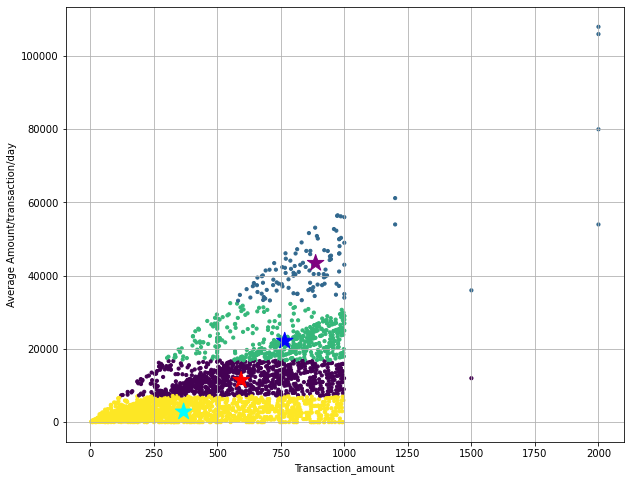

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('/content/creditcardcsvpresent.csv')
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (3075, 12)


,Merchant_id,Transaction date,Average Amount/transaction/day,Transaction_amount,Is declined,Total Number of declines/day,isForeignTransaction,isHighRiskCountry,Daily_chargeback_avg_amt,6_month_avg_chbk_amt,6-month_chbk_freq,isFradulent
0,3160040998,NaN,100.0,3000.0,N,5,Y,Y,0,0.0,0,Y
1,3160040998,NaN,100.0,4300.0,N,5,Y,Y,0,0.0,0,Y
2,3160041896,NaN,185.5,4823.0,Y,5,N,N,0,0.0,0,Y
3,3160141996,NaN,185.5,5008.5,Y,8,N,N,0,0.0,0,Y
4,3160241992,NaN,500.0,26000.0,N,0,Y,Y,800,677.2,6,Y


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3075 entries, 0 to 3074
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Merchant_id                     3075 non-null   int64  
 1   Transaction date                0 non-null      float64
 2   Average Amount/transaction/day  3075 non-null   float64
 3   Transaction_amount              3075 non-null   float64
 4   Is declined                     3075 non-null   object 
 5   Total Number of declines/day    3075 non-null   int64  
 6   isForeignTransaction            3075 non-null   object 
 7   isHighRiskCountry               3075 non-null   object 
 8   Daily_chargeback_avg_amt        3075 non-null   int64  
 9   6_month_avg_chbk_amt            3075 non-null   float64
 10  6-month_chbk_freq               3075 non-null   int64  
 11  isFradulent                     3075 non-null   object 
dtypes: float64(4), int64(4), object(4)

## 1. Análisis descriptivo de los datos

Primero se clasifican las columnas:

| Tipo | Columnas |
|---|---|
| **Identificador** (no se analiza estadísticamente) | `Merchant_id` |
| **Numéricas** | `Transaction date`, `Average Amount/transaction/day`, `Transaction_amount`, `Total Number of declines/day`, `Daily_chargeback_avg_amt`, `6_month_avg_chbk_amt`, `6-month_chbk_freq` |
| **Categóricas (Y/N)** | `Is declined`, `isForeignTransaction`, `isHighRiskCountry`, `isFradulent` (variable objetivo) |

`Merchant_id` es numérica en su tipo de dato, pero es un **código** del comercio: calcular su media o su desviación no tiene sentido, por eso se excluye.

### 1.1 Estadísticos de las variables numéricas

In [4]:
num_cols = ['Transaction date', 'Average Amount/transaction/day', 'Transaction_amount',
            'Total Number of declines/day', 'Daily_chargeback_avg_amt',
            '6_month_avg_chbk_amt', '6-month_chbk_freq']

estadisticos = df[num_cols].describe().T
estadisticos['mediana']   = df[num_cols].median()
estadisticos['moda']      = df[num_cols].mode().iloc[0]
estadisticos['varianza']  = df[num_cols].var()
estadisticos['asimetria'] = df[num_cols].skew()
estadisticos['curtosis']  = df[num_cols].kurt()
estadisticos.round(2)

,count,mean,std,min,25%,50%,75%,max,mediana,moda,varianza,asimetria,curtosis
Transaction date,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Average Amount/transaction/day,3075.0,515.03,291.91,4.01,269.79,502.55,765.27,2000.0,502.55,500.0,8.520968e+04,0.18,-0.37
Transaction_amount,3075.0,9876.40,10135.33,0.00,2408.78,6698.89,14422.57,108000.0,6698.89,0.0,1.027249e+08,2.11,8.49
Total Number of declines/day,3075.0,0.96,2.19,0.00,0.00,0.00,0.00,20.0,0.00,0.0,4.810000e+00,2.69,8.87
Daily_chargeback_avg_amt,3075.0,55.74,206.63,0.00,0.00,0.00,0.00,998.0,0.00,0.0,4.269793e+04,3.57,11.11
6_month_avg_chbk_amt,3075.0,40.02,155.97,0.00,0.00,0.00,0.00,998.0,0.00,0.0,2.432628e+04,4.04,15.68
6-month_chbk_freq,3075.0,0.39,1.55,0.00,0.00,0.00,0.00,9.0,0.00,0.0,2.400000e+00,4.05,15.36


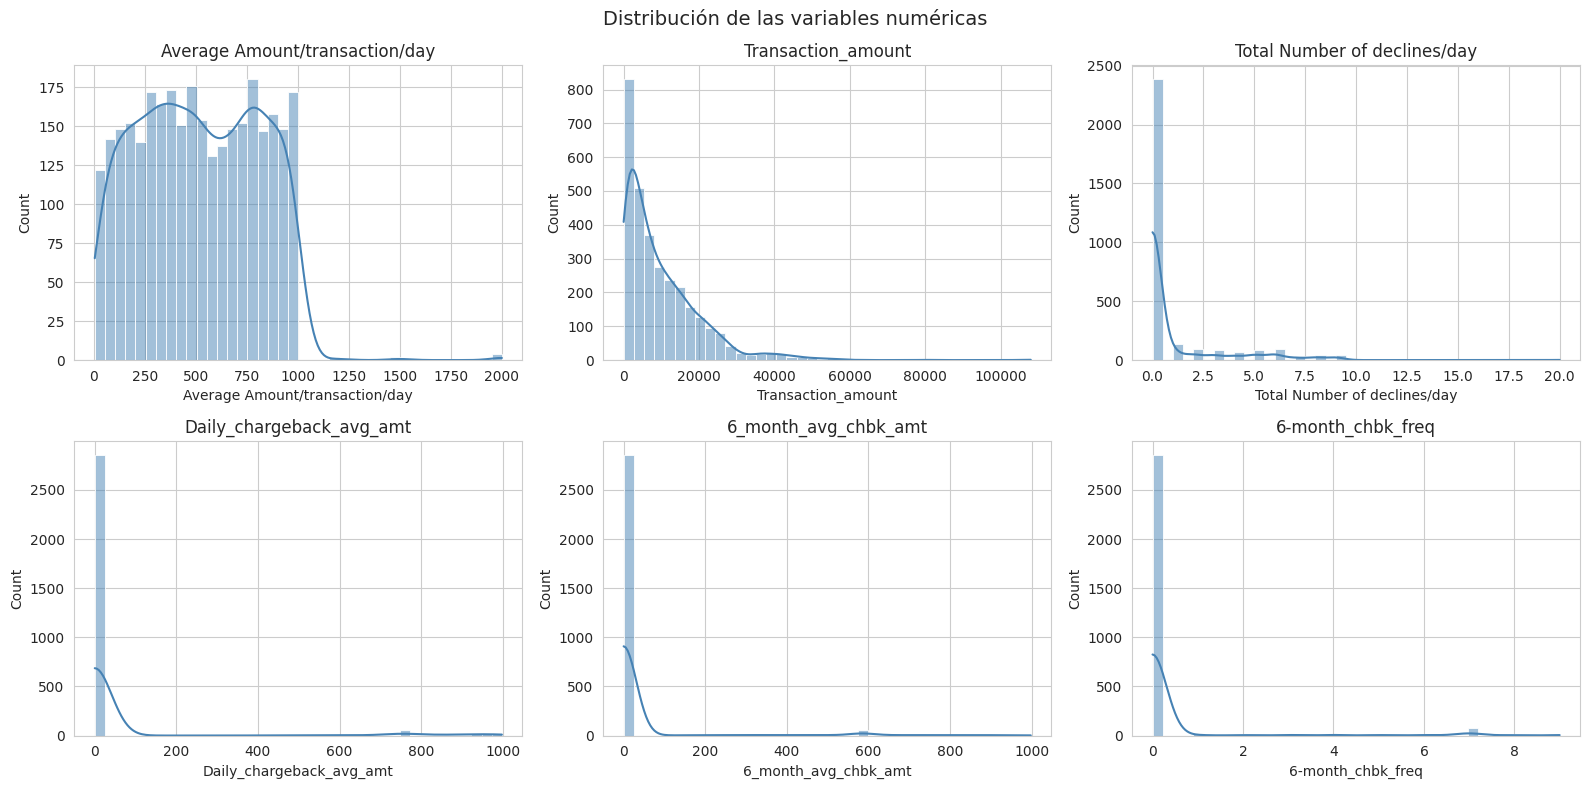

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols[1:]):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color='steelblue')
    ax.set_title(col)
plt.suptitle('Distribución de las variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación de los estadísticos:**

- **`Transaction date`** tiene `count = 0`: la columna está **100 % vacía** (se trata en el punto 2).
- **`Average Amount/transaction/day`**: media ≈ 515 y mediana ≈ 503, muy parecidas, asimetría ≈ 0,18 → distribución casi simétrica, valores entre 4 y 2.000.
- **`Transaction_amount`**: media ≈ 9.876 pero mediana ≈ 6.699 y máximo de 108.000 → **sesgo fuerte a la derecha** (asimetría ≈ 2,1); hay pocas transacciones muy grandes que levantan la media.
- **`Total Number of declines/day`**, **`Daily_chargeback_avg_amt`**, **`6_month_avg_chbk_amt`** y **`6-month_chbk_freq`**: la mediana y el percentil 75 son **0**. Es decir, más del 75 % de las transacciones no tienen rechazos ni contracargos; los valores distintos de cero son pocos y extremos (asimetrías entre 2,7 y 4). Son variables tipo "evento raro", justamente las que suelen acompañar al fraude.
- Las escalas son muy distintas (de 0–9 hasta 0–108.000). Esto obliga a **estandarizar** antes de aplicar K-means, porque el algoritmo usa distancias euclidianas y, sin escalar, `Transaction_amount` dominaría por completo el agrupamiento.

### 1.2 Variables categóricas: categorías y frecuencias

In [6]:
cat_cols = ['Is declined', 'isForeignTransaction', 'isHighRiskCountry', 'isFradulent']

for col in cat_cols:
    tabla = pd.DataFrame({
        'frecuencia': df[col].value_counts(),
        'porcentaje (%)': (df[col].value_counts(normalize=True) * 100).round(2)
    })
    print(f'--- {col} | categorías: {list(df[col].unique())}')
    print(tabla, '\n')

--- Is declined | categorías: ['N', 'Y']
             frecuencia  porcentaje (%)
Is declined                            
N                  3018           98.15
Y                    57            1.85 

--- isForeignTransaction | categorías: ['Y', 'N']
                      frecuencia  porcentaje (%)
isForeignTransaction                            
N                           2369           77.04
Y                            706           22.96 

--- isHighRiskCountry | categorías: ['Y', 'N']
                   frecuencia  porcentaje (%)
isHighRiskCountry                            
N                        2870           93.33
Y                         205            6.67 

--- isFradulent | categorías: ['Y', 'N']
             frecuencia  porcentaje (%)
isFradulent                            
N                  2627           85.43
Y                   448           14.57 



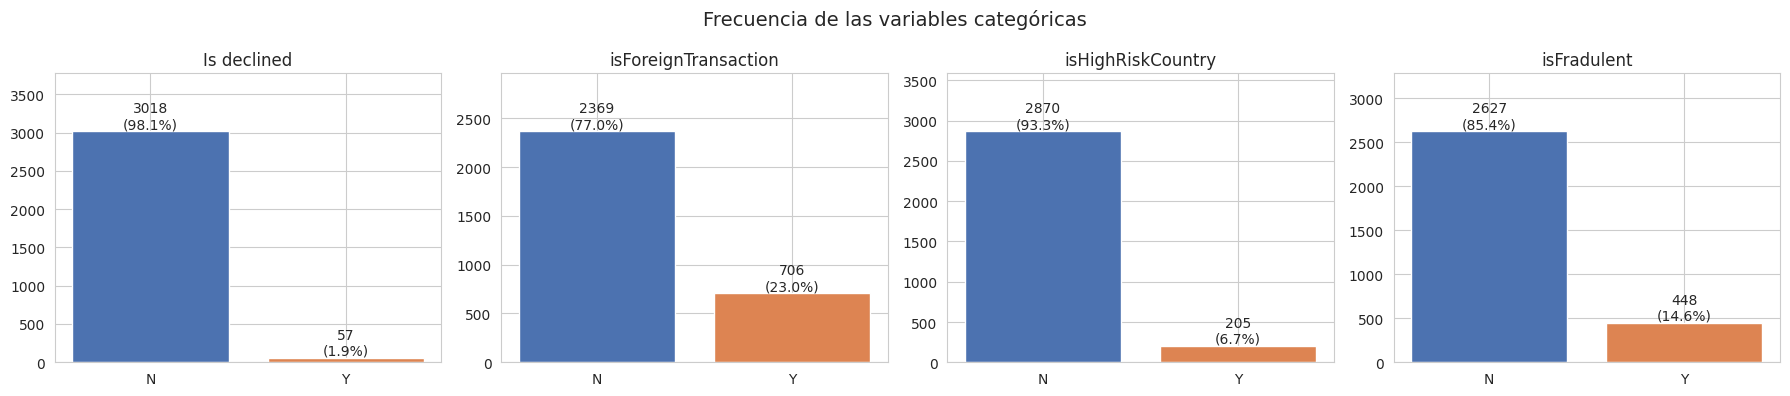

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_cols):
    conteo = df[col].value_counts()
    ax.bar(conteo.index, conteo.values, color=['#4C72B0', '#DD8452'])
    for i, v in enumerate(conteo.values):
        ax.text(i, v, f'{v}\n({v/len(df):.1%})', ha='center', va='bottom')
    ax.set_title(col)
    ax.set_ylim(0, conteo.max() * 1.25)
plt.suptitle('Frecuencia de las variables categóricas', fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación:**

- Todas las variables categóricas son **binarias** con las categorías `Y` (sí) y `N` (no).
- `Is declined`: solo el **1,85 %** (57) de las transacciones fueron rechazadas.
- `isForeignTransaction`: el **23 %** (706) son transacciones extranjeras.
- `isHighRiskCountry`: el **6,7 %** (205) provienen de países de alto riesgo.
- `isFradulent` (variable objetivo): **448 fraudes (14,6 %)** frente a 2.627 legítimas (85,4 %). Es un conjunto **desbalanceado**: un modelo que dijera "nadie es fraude" ya tendría 85,4 % de exactitud. Este valor es la **línea base** contra la que se deben comparar los modelos del punto 4.

### 1.3 Matriz de correlaciones

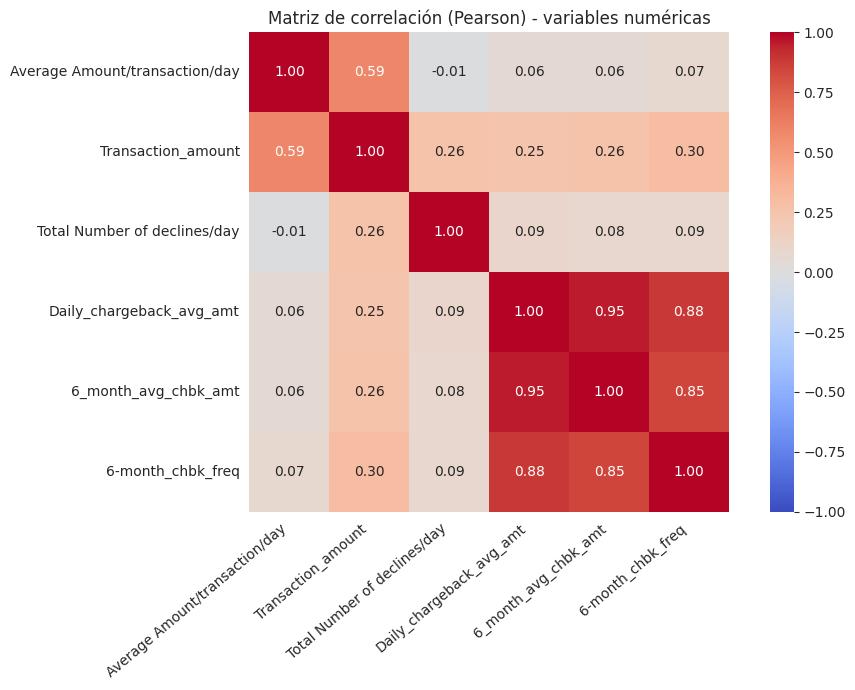

In [8]:
num_validas = num_cols[1:]   # Transaction date está vacía, no se puede correlacionar
corr = df[num_validas].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matriz de correlación (Pearson) - variables numéricas')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

Como complemento, se codifican las variables categóricas como 0/1 (`N`=0, `Y`=1) para ver cómo se relaciona cada variable con el fraude:

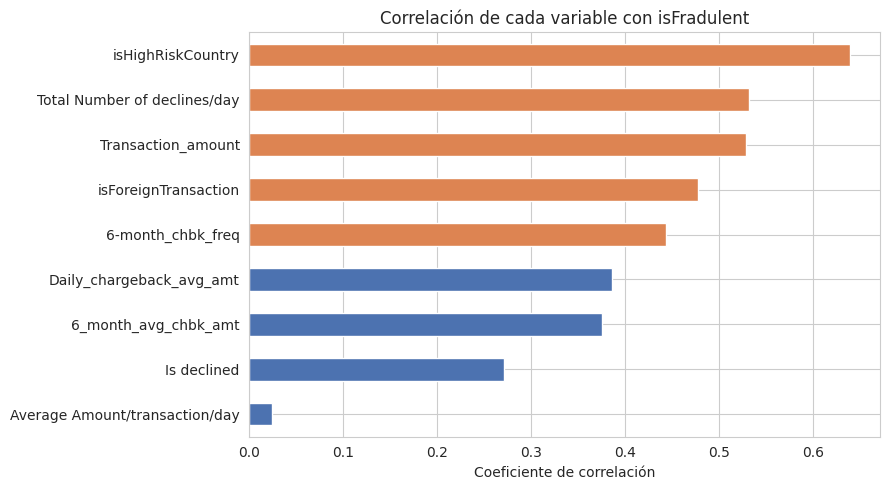

,isFradulent
Average Amount/transaction/day,0.02
Is declined,0.27
6_month_avg_chbk_amt,0.38
Daily_chargeback_avg_amt,0.39
6-month_chbk_freq,0.44
isForeignTransaction,0.48
Transaction_amount,0.53
Total Number of declines/day,0.53
isHighRiskCountry,0.64


In [9]:
df_cod = df.drop(columns=['Merchant_id', 'Transaction date']).copy()
for col in cat_cols:
    df_cod[col] = df_cod[col].map({'N': 0, 'Y': 1})

corr_fraude = df_cod.corr()['isFradulent'].drop('isFradulent').sort_values()
plt.figure(figsize=(9, 5))
corr_fraude.plot(kind='barh', color=['#DD8452' if v > 0.4 else '#4C72B0' for v in corr_fraude])
plt.title('Correlación de cada variable con isFradulent')
plt.xlabel('Coeficiente de correlación')
plt.tight_layout()
plt.show()
corr_fraude.round(2)

**Análisis de la matriz de correlaciones:**

1. **Grupo de contracargos muy correlacionado:** `Daily_chargeback_avg_amt`, `6_month_avg_chbk_amt` y `6-month_chbk_freq` tienen correlaciones de **0,85 a 0,95**. Miden prácticamente lo mismo (historial de contracargos del comercio), así que hay **redundancia / multicolinealidad**: en la práctica aportan casi la misma información.
2. **Montos:** `Transaction_amount` y `Average Amount/transaction/day` tienen correlación **positiva moderada (0,59)**: los comercios con mayor ticket promedio tienden a tener transacciones más grandes, como es lógico.
3. **Correlaciones débiles:** `Total Number of declines/day` casi no se relaciona con el monto promedio (−0,01) ni con los contracargos (≈ 0,09). Es una fuente de información independiente.
4. **Relación con el fraude** (gráfico de barras): las variables más asociadas al fraude son `isHighRiskCountry` (0,64), `Transaction_amount` (0,53), `Total Number of declines/day` (0,53) y `isForeignTransaction` (0,48), seguidas del historial de contracargos (≈ 0,4). En cambio, `Average Amount/transaction/day` casi no tiene relación (0,02).
5. No hay correlaciones negativas relevantes entre las variables.

## 2. Tratamiento de datos faltantes

In [10]:
faltantes = pd.DataFrame({
    'faltantes': df.isnull().sum(),
    'porcentaje (%)': (df.isnull().mean() * 100).round(2)
})
faltantes

,faltantes,porcentaje (%)
Merchant_id,0,0.0
Transaction date,3075,100.0
Average Amount/transaction/day,0,0.0
Transaction_amount,0,0.0
Is declined,0,0.0
Total Number of declines/day,0,0.0
isForeignTransaction,0,0.0
isHighRiskCountry,0,0.0
Daily_chargeback_avg_amt,0,0.0
6_month_avg_chbk_amt,0,0.0


**Decisión y justificación:**

- La única columna con faltantes es **`Transaction date`**, y le faltan **los 3.075 valores (100 %)**.
- **No se pueden eliminar registros:** como todas las filas tienen ese valor vacío, borrar los registros con faltantes dejaría el conjunto de datos **sin ninguna fila**.
- **Tampoco se puede imputar con media, mediana o moda:** esas medidas se calculan a partir de los valores existentes y aquí **no existe ningún valor**, así que no hay de dónde calcularlas. Rellenar con un valor inventado (por ejemplo 0) crearía una columna constante que no aporta información y solo agrega ruido.
- **Decisión: eliminar la columna `Transaction date`.** Es la opción correcta cuando una variable no tiene información.
- El resto de columnas no tienen faltantes, por lo que no requieren tratamiento.
- Además se elimina `Merchant_id` del modelado porque es un identificador; incluirlo en K-means haría que el algoritmo agrupe por número de comercio, lo que no tiene significado.

In [11]:
df_limpio = df.drop(columns=['Transaction date', 'Merchant_id'])
print('Faltantes restantes:', df_limpio.isnull().sum().sum())
print('Dimensiones finales:', df_limpio.shape)

Faltantes restantes: 0
Dimensiones finales: (3075, 10)


## 3. Agrupamiento con K-means

### 3.1 Preparación de los datos
- Las variables categóricas se convierten a 0/1.
- `isFradulent` se **separa** como etiqueta real (`y`): K-means es no supervisado, no debe "ver" la respuesta. Solo se usa al final para medir la exactitud.
- Las variables se **estandarizan** (media 0, desviación 1) con `StandardScaler`, por la gran diferencia de escalas vista en el punto 1.

In [12]:
datos = df_limpio.copy()
for col in cat_cols:
    datos[col] = datos[col].map({'N': 0, 'Y': 1})

y = datos.pop('isFradulent')          # etiqueta real (solo para evaluar)
X = datos                              # 9 variables de entrada

escalador = StandardScaler()
X_esc = escalador.fit_transform(X)

print('Variables usadas:', list(X.columns))
print('Forma de X:', X_esc.shape)

Variables usadas: ['Average Amount/transaction/day', 'Transaction_amount', 'Is declined', 'Total Number of declines/day', 'isForeignTransaction', 'isHighRiskCountry', 'Daily_chargeback_avg_amt', '6_month_avg_chbk_amt', '6-month_chbk_freq']
Forma de X: (3075, 9)


### 3.2 Técnica del codo
Se entrena K-means con k = 1 … 10 y se grafica la **inercia** (WCSS: suma de distancias al cuadrado de cada punto a su centroide).

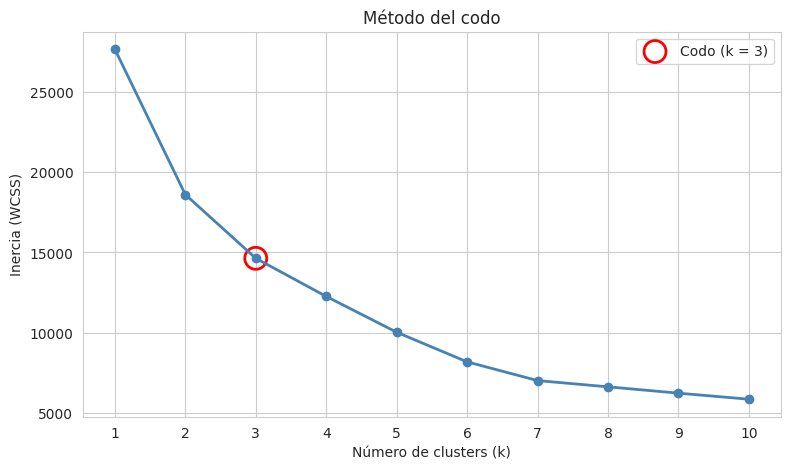

,k,inercia,reducción vs k-1 (%)
0,1,27675.0,NaN
1,2,18611.0,32.8
2,3,14635.0,21.4
3,4,12259.0,16.2
4,5,10024.0,18.2
5,6,8176.0,18.4
6,7,7009.0,14.3
7,8,6619.0,5.6
8,9,6225.0,6.0
9,10,5847.0,6.1


In [13]:
inercias = []
rango_k = range(1, 11)
for k in rango_k:
    km = KMeans(n_clusters=k, max_iter=1000, random_state=0, n_init=10)
    km.fit(X_esc)
    inercias.append(km.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(rango_k, inercias, 'o-', color='steelblue', linewidth=2)
plt.scatter([3], [inercias[2]], s=250, facecolors='none', edgecolors='red', linewidths=2, label='Codo (k = 3)')
plt.xticks(rango_k)
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia (WCSS)')
plt.title('Método del codo')
plt.legend()
plt.show()

reduccion = pd.DataFrame({'k': list(rango_k), 'inercia': np.round(inercias, 0)})
reduccion['reducción vs k-1 (%)'] = (-reduccion['inercia'].pct_change() * 100).round(1)
reduccion

**Análisis del codo:**

- De k=1 a k=2 la inercia cae cerca de un **33 %** y de k=2 a k=3 otro **20 %**: son las ganancias más grandes.
- A partir de k=3 la curva se vuelve más suave: cada cluster adicional reduce la inercia en porcentajes parecidos entre sí (≈ 14–18 % hasta k=7 y ≈ 6 % después), sin otro quiebre marcado; es decir, se agregan grupos sin una mejora estructural clara.
- **Número de clusters ideal según el codo: k = 3.** Es el punto donde la curva "dobla" y deja de compensar seguir aumentando k. (El codo no es perfectamente marcado, algo frecuente con datos reales, por eso también se evalúan k=2 y k=4.)

### 3.3 Modelos con 2, 3 y 4 clusters

Se usan los hiperparámetros pedidos: `max_iter=1000` y `random_state=0`.

> Se agrega explícitamente `n_init=10`. En versiones recientes de scikit-learn (≥ 1.4) el valor por defecto cambió a `'auto'` (una sola inicialización), lo que hace que el resultado dependa de la versión instalada. Fijar `n_init=10` reproduce el comportamiento clásico (10 inicializaciones y se queda con la mejor), así el resultado es el mismo en Colab o en cualquier equipo.

In [14]:
modelos = {}
for k in [2, 3, 4]:
    modelo = KMeans(n_clusters=k, max_iter=1000, random_state=0, n_init=10)
    modelo.fit(X_esc)
    modelos[k] = modelo
    print(f'k={k} -> iteraciones: {modelo.n_iter_:>3} | inercia: {modelo.inertia_:,.0f} | '
          f'tamaño de clusters: {np.bincount(modelo.labels_).tolist()}')

k=2 -> iteraciones:   3 | inercia: 18,611 | tamaño de clusters: [206, 2869]
k=3 -> iteraciones:  14 | inercia: 14,635 | tamaño de clusters: [240, 2630, 205]
k=4 -> iteraciones:   8 | inercia: 12,259 | tamaño de clusters: [1427, 1267, 204, 177]


## 4. Análisis de resultados

### 4.1 ¿Cómo se calcula la exactitud en un modelo de clustering?
K-means asigna números de cluster (0, 1, 2…) que **no significan** "fraude" o "no fraude". Para calcular el `accuracy`:

1. Se cruza cada cluster con la etiqueta real `isFradulent`.
2. Cada cluster se etiqueta con la **clase mayoritaria** de sus elementos (si la mayoría son fraudes, el cluster se considera "fraude").
3. Se compara esa predicción con la etiqueta real usando `accuracy_score`.

Así se puede comparar modelos con distinto número de clusters.

In [15]:
def evaluar(modelo, y):
    etiquetas = modelo.labels_
    tabla = pd.crosstab(etiquetas, y.map({0: 'N (legítima)', 1: 'Y (fraude)'}))
    tabla.index.name = 'cluster'
    mapeo = {c: y[etiquetas == c].mode()[0] for c in np.unique(etiquetas)}
    y_pred = np.array([mapeo[c] for c in etiquetas])
    return accuracy_score(y, y_pred), tabla, mapeo, y_pred

resultados = {}
for k, modelo in modelos.items():
    acc, tabla, mapeo, y_pred = evaluar(modelo, y)
    resultados[k] = {'accuracy': acc, 'y_pred': y_pred}
    tabla['clase asignada'] = [('Y (fraude)' if mapeo[c] == 1 else 'N (legítima)') for c in tabla.index]
    print(f'================ k = {k} | accuracy = {acc:.4f} ({acc:.2%}) ================')
    print(tabla, '\n')

================ k = 2 | accuracy = 0.8777 (87.77%) ================
isFradulent  N (legítima)  Y (fraude) clase asignada
cluster                                             
0                      67         139     Y (fraude)
1                    2560         309   N (legítima) 

================ k = 3 | accuracy = 0.9528 (95.28%) ================
isFradulent  N (legítima)  Y (fraude) clase asignada
cluster                                             
0                       4         236     Y (fraude)
1                    2556          74   N (legítima)
2                      67         138     Y (fraude) 

================ k = 4 | accuracy = 0.9353 (93.53%) ================
isFradulent  N (legítima)  Y (fraude) clase asignada
cluster                                             
0                    1385          42   N (legítima)
1                    1176          91   N (legítima)
2                      66         138     Y (fraude)
3                       0         177     Y (fr

### 4.2 Gráficas de los clusters

Se grafica cada modelo sobre las dos variables de monto (`Transaction_amount` vs `Average Amount/transaction/day`), como en la imagen de ejemplo. Los centroides se devuelven a la escala original (`inverse_transform`) y se marcan con una ✕.

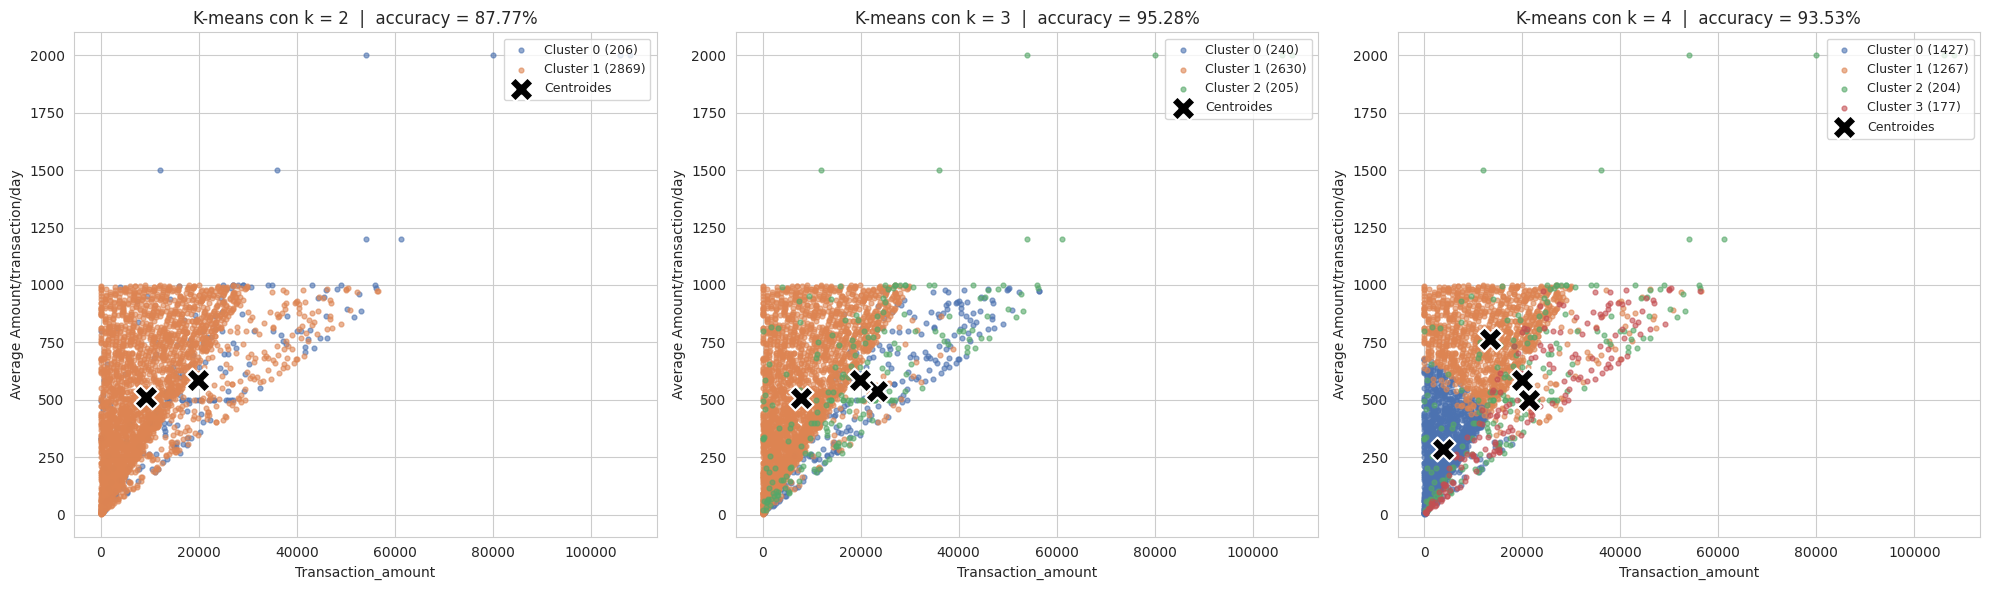

In [16]:
ix_x = list(X.columns).index('Transaction_amount')
ix_y = list(X.columns).index('Average Amount/transaction/day')
colores = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (k, modelo) in zip(axes, modelos.items()):
    centroides = escalador.inverse_transform(modelo.cluster_centers_)
    for c in range(k):
        m = modelo.labels_ == c
        ax.scatter(X.loc[m, 'Transaction_amount'], X.loc[m, 'Average Amount/transaction/day'],
                   s=12, alpha=0.6, color=colores[c], label=f'Cluster {c} ({m.sum()})')
    ax.scatter(centroides[:, ix_x], centroides[:, ix_y], marker='X', s=300,
               c='black', edgecolors='white', linewidths=1.5, label='Centroides')
    ax.set_title(f'K-means con k = {k}  |  accuracy = {resultados[k]["accuracy"]:.2%}')
    ax.set_xlabel('Transaction_amount')
    ax.set_ylabel('Average Amount/transaction/day')
    ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

Como el modelo usa 9 variables, una vista en 2 variables no muestra toda la separación. Para verla mejor se grafica también contra `Total Number of declines/day`, una de las variables más ligadas al fraude, junto con las etiquetas reales:

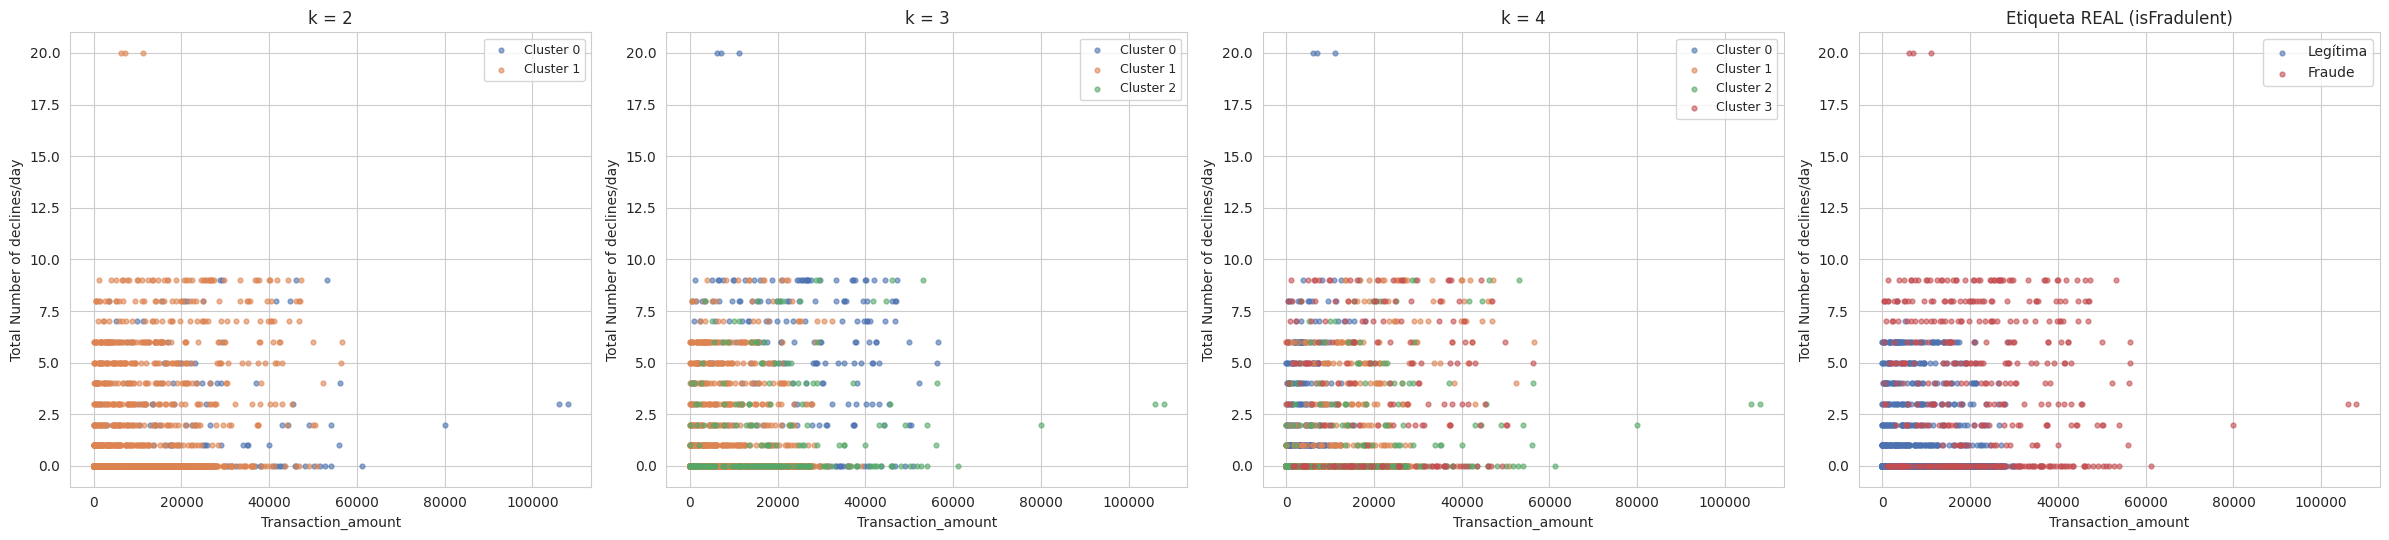

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
for ax, (k, modelo) in zip(axes[:3], modelos.items()):
    for c in range(k):
        m = modelo.labels_ == c
        ax.scatter(X.loc[m, 'Transaction_amount'], X.loc[m, 'Total Number of declines/day'],
                   s=12, alpha=0.6, color=colores[c], label=f'Cluster {c}')
    ax.set_title(f'k = {k}')
    ax.set_xlabel('Transaction_amount'); ax.set_ylabel('Total Number of declines/day')
    ax.legend(fontsize=9)

for clase, color, nombre in [(0, '#4C72B0', 'Legítima'), (1, '#C44E52', 'Fraude')]:
    m = y == clase
    axes[3].scatter(X.loc[m, 'Transaction_amount'], X.loc[m, 'Total Number of declines/day'],
                    s=12, alpha=0.6, color=color, label=nombre)
axes[3].set_title('Etiqueta REAL (isFradulent)')
axes[3].set_xlabel('Transaction_amount'); axes[3].set_ylabel('Total Number of declines/day')
axes[3].legend()
plt.tight_layout()
plt.show()

### 4.3 Comparación de exactitudes

Línea base (predecir siempre "no fraude"): 85.43%


,k,accuracy,accuracy (%),mejora vs línea base (pp)
0,2,0.877724,87.77,2.34
1,3,0.952846,95.28,9.85
2,4,0.935285,93.53,8.10


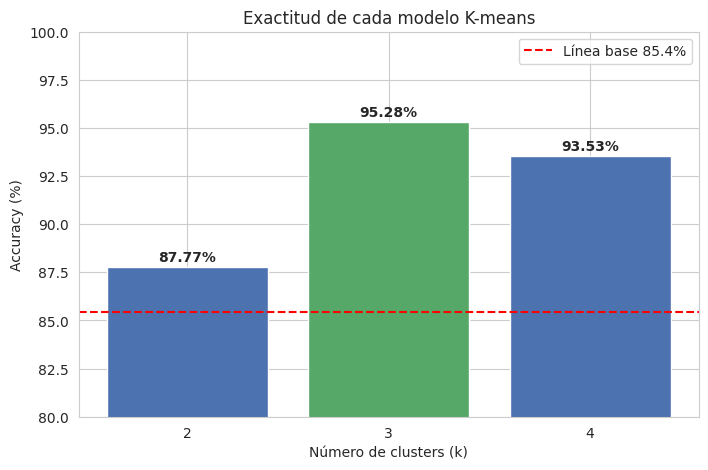

Modelo con mayor exactitud: k = 3


In [18]:
base = (y == 0).mean()
comparacion = pd.DataFrame({
    'k': list(resultados.keys()),
    'accuracy': [r['accuracy'] for r in resultados.values()],
})
comparacion['accuracy (%)'] = (comparacion['accuracy'] * 100).round(2)
comparacion['mejora vs línea base (pp)'] = ((comparacion['accuracy'] - base) * 100).round(2)
print(f'Línea base (predecir siempre "no fraude"): {base:.2%}')
display(comparacion)

plt.figure(figsize=(8, 5))
barras = plt.bar(comparacion['k'].astype(str), comparacion['accuracy'] * 100,
                 color=['#4C72B0' if a < comparacion['accuracy'].max() else '#55A868' for a in comparacion['accuracy']])
plt.axhline(base * 100, color='red', linestyle='--', label=f'Línea base {base:.1%}')
for b, a in zip(barras, comparacion['accuracy']):
    plt.text(b.get_x() + b.get_width() / 2, a * 100 + 0.3, f'{a:.2%}', ha='center', fontweight='bold')
plt.ylim(80, 100)
plt.xlabel('Número de clusters (k)'); plt.ylabel('Accuracy (%)')
plt.title('Exactitud de cada modelo K-means')
plt.legend()
plt.show()

mejor_k = int(comparacion.loc[comparacion['accuracy'].idxmax(), 'k'])
print(f'Modelo con mayor exactitud: k = {mejor_k}')

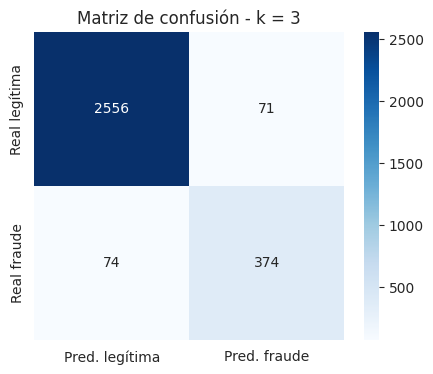

Fraudes detectados: 374 de 448 (83.5%)
Falsas alarmas: 71 de 2627 legítimas (2.7%)


In [19]:
# Matriz de confusión del mejor modelo
cm = confusion_matrix(y, resultados[mejor_k]['y_pred'])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred. legítima', 'Pred. fraude'], yticklabels=['Real legítima', 'Real fraude'])
plt.title(f'Matriz de confusión - k = {mejor_k}')
plt.show()
print(f'Fraudes detectados: {cm[1,1]} de {cm[1].sum()} ({cm[1,1]/cm[1].sum():.1%})')
print(f'Falsas alarmas: {cm[0,1]} de {cm[0].sum()} legítimas ({cm[0,1]/cm[0].sum():.1%})')

In [20]:
# Perfil promedio de cada cluster del mejor modelo (escala original)
perfil = X.copy()
perfil['isFradulent'] = y
perfil['cluster'] = modelos[mejor_k].labels_
resumen = perfil.groupby('cluster').mean().round(2)
resumen.insert(0, 'n', perfil['cluster'].value_counts().sort_index())
resumen.T

cluster,0,1,2
n,240.00,2630.00,205.00
Average Amount/transaction/day,538.29,507.36,586.09
Transaction_amount,23339.92,7864.53,19925.06
Is declined,0.01,0.00,0.24
Total Number of declines/day,4.69,0.56,1.67
isForeignTransaction,0.95,0.16,0.32
isHighRiskCountry,0.74,0.00,0.14
Daily_chargeback_avg_amt,5.59,1.82,806.22
6_month_avg_chbk_amt,1.69,1.02,585.29
6-month_chbk_freq,0.02,0.01,5.72


**Análisis de las exactitudes:**

| k | Accuracy | Lectura |
|---|---|---|
| 2 | ≈ 87,8 % | Apenas supera la línea base (85,4 %). Con solo 2 grupos, gran parte de los fraudes quedan mezclados en el cluster mayoritario de transacciones legítimas. |
| **3** | **≈ 95,3 %** | **La mayor exactitud.** Aparece un cluster casi puro de fraude y otro de transacciones "sospechosas" (con historial de contracargos) donde también predomina el fraude. |
| 4 | ≈ 93,5 % | Baja respecto a k=3: el cuarto cluster divide en dos el grupo grande de transacciones legítimas (que ya estaba bien clasificado) y reorganiza los grupos de fraude con un poco más de error. |

**¿Concuerda con el valor del codo?** **Sí.** El método del codo sugirió **k = 3** y el modelo con mayor exactitud también es **k = 3**. Las dos técnicas, una no supervisada (inercia) y otra que usa la etiqueta real (accuracy), llegan al mismo número de clusters, lo que da confianza en la elección.

## Conclusiones

1. **Calidad de los datos:** la columna `Transaction date` estaba completamente vacía y se eliminó; ninguna otra variable tenía faltantes. `Merchant_id` se excluyó por ser un identificador.
2. **Escalado indispensable:** las variables tienen rangos muy diferentes (0–9 vs 0–108.000). Sin estandarizar, K-means agruparía casi solo por `Transaction_amount`.
3. **Variables redundantes:** las tres variables de contracargos están muy correlacionadas (0,85–0,95). Se podría usar solo una o reducir dimensión con PCA sin perder mucha información.
4. **Señales de fraude:** las variables más asociadas con el fraude son país de alto riesgo, monto de la transacción, número de rechazos diarios y transacción extranjera. El monto promedio diario del comercio prácticamente no aporta.
5. **Número de clusters:** el codo y la exactitud coinciden en **k = 3**, con ≈ 95 % de exactitud frente al 85,4 % de la línea base.
6. **Interpretación de los 3 grupos:** (a) un grupo grande de transacciones **normales** (montos moderados, sin rechazos, sin contracargos, casi sin fraude); (b) un grupo con **alto historial de contracargos**, mayoritariamente fraudulento; (c) un grupo de **alto riesgo** (montos altos, varios rechazos diarios, países de alto riesgo / extranjeras) prácticamente todo fraude.
7. **Precaución con el accuracy:** como los datos están desbalanceados (14,6 % fraude), el accuracy por sí solo puede engañar. Por eso se compara contra la línea base y se revisa la matriz de confusión (fraudes detectados y falsas alarmas). Para un sistema real convendría además medir *recall* y *precision* de la clase fraude.
8. **Alcance:** K-means no es un clasificador; aquí resultó útil porque el fraude forma grupos naturalmente separados. Un modelo supervisado (regresión logística, árboles, etc.) probablemente superaría esta exactitud, pero el clustering confirma que la estructura de los datos ya separa bien los fraudes.